# See, Detect, Understand: Computer Vision introduction (by Statistics and Data Science Society)


### Learning goals

By the end of this introductory example, you should be able to:

- Read an image's shape and explain its RGB pixel values.
- Apply averaging and Sobel filters, then compare a filter response before and after ReLU.
- Prepare an image for an existing CNN and run a prediction.
- Explain the difference between inference, training and transfer learning.
- Interpret model scores and identify limitations of a fixed category list.

### Workshop route

| Section | Activity | Exercises |
| --- | --- | --- |
| 0. Setup | Load the tools and sample image | Provided code |
| 1. Image representation | Inspect pixels and RGB channels | Exercise 1 |
| 2. Image preparation and filters | Resize, apply averaging and Sobel kernels, then try ReLU | Exercises 2-3 |
| 3. Image classification | Load the CNN, batch, preprocess and predict | Exercises 4-6 |
| 4. Changing the input | Compare predictions after RGB averaging and Gaussian blur | Supplied comparisons |
| 5. Your turn | Investigate a new image and explain its results | Short challenge |
| 6. Inside a CNN | Compare another fixed filter with learned feature maps | Optional exploration |

##How to use this template
1. Install Python 3.12, VS Code, and Microsoft's Python and Jupyter extensions.
2. Download and extract the workshop repository. In VS Code, choose File > Open Folder and open the week-10-cv folder.
3. Create and activate a Python 3.12 virtual environment. In the VS Code terminal, install the workshop packages using python -m pip install -r requirements.txt.
4. Open the participant notebook. Click Select Kernel > Python Environments and select the environment created in Step 3.
5. Run code cells in order using the play button or Shift+Enter.
6. Replace the None values marked TODO in Exercises 1-6 with your code. An unfinished exercise stops with a message asking you to complete it.
The first run downloads a sample photo, pretrained model weights and the ImageNet label lookup. Internet access is required. A CPU is sufficient; you do not need a GPU.

# Section 0: Setup and sample image

The libraries have different jobs: **NumPy** stores numbers, **Pillow** opens images, **Matplotlib** displays them, and **TensorFlow/Keras** runs the model. `import` makes these tools available to Python.

Colab normally includes these packages. Run this cell first. If an import fails, try a fresh standard runtime before changing packages.

In [1]:
import io
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image, ImageOps, ImageFilter, UnidentifiedImageError
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input, decode_predictions

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
NumPy: 2.5.3


## A common example for everyone

Keep `image_source = "sample"` for your first run. Everyone will use the same Labrador photograph from a TensorFlow tutorial. Later, change it to `"upload"` to select one JPEG or PNG from your computer.

The supplied code handles downloading and file opening so you can focus on the vision concepts. `convert("RGB")` ensures the image has three colour channels. `exif_transpose` respects orientation information from a camera.

**Image credit:** *YellowLabradorLooking new.jpg*, original photo by Elf, derivative/retouch by Djmirko and FT2, via [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:YellowLabradorLooking_new.jpg), [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/). The image transformations shown in this notebook include resizing, channel views, blur and filter responses. The transformed sample image views retain this image credit and licence.

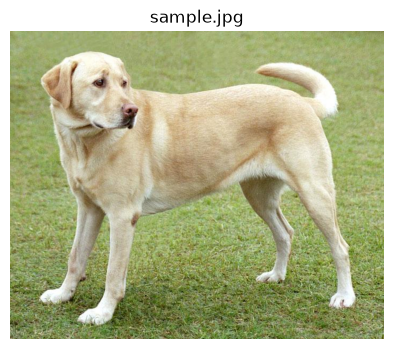

In [2]:
from pathlib import Path

# Change the filename to try another image.
image_path = Path("data/images/sample.jpg")

with Image.open(image_path) as image_file:
    img = ImageOps.exif_transpose(image_file).convert("RGB")

image_name = image_path.name

plt.figure(figsize=(6, 4))
plt.imshow(img)
plt.title(image_name)
plt.axis("off")
plt.show()

# Section 1: How does a computer see?

> **Guiding question 1:** What numbers represent this photograph?

An RGB image has shape **(height, width, 3)**. Each pixel contains red, green and blue channel values. In this 8-bit representation, each value ranges from 0 to 255.

**Exercise 1:** Convert `img` to a NumPy array named `pixels`. Then read the shape and the top-left pixel.

<details><summary>Hint</summary>
NumPy's `asarray` function converts an image into an array. Python starts indexing from zero, so `pixels[0, 0]` selects the first row and first column.
</details>

In [3]:
# TODO 1: Replace None with a NumPy array made from img.
pixels = np.asarray(img)
if pixels is None:
    raise NotImplementedError("Complete Exercise 1 before continuing.")

print("Shape (height, width, channels):", pixels.shape)
print("First pixel [R, G, B]:", pixels[0, 0]) #the three channel values for the first pixel (most topleft)
print("Red-channel values in a 5x5 patch:") #only the red channel values in the 25 pixels at the top left
print(pixels[:5, :5, 0])

Shape (height, width, channels): (577, 700, 3)
First pixel [R, G, B]: [162 167 101]
Red-channel values in a 5x5 patch:
[[162 157 151 151 154]
 [159 156 152 152 154]
 [153 154 154 155 155]
 [148 151 154 156 154]
 [144 148 153 152 153]]


## RGB channels

The supplied cell shows the three channels as intensity plots. All panels use the same 0-255 range. These are three measurements at each location in the same photograph.

**Pause and discuss:** What colour does `[255, 0, 0]` represent? What about `[0, 0, 0]` and `[255, 255, 255]`?

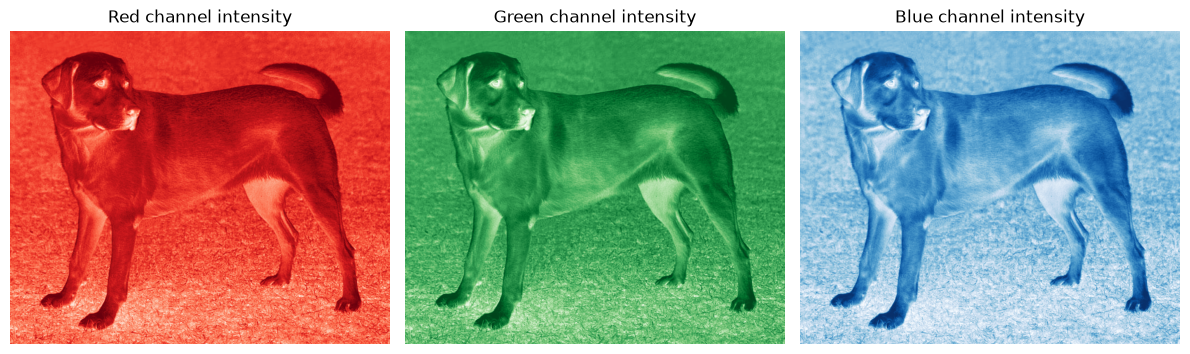

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for channel, (name, colour_map) in enumerate(
    [("Red", "Reds"), ("Green", "Greens"), ("Blue", "Blues")]
):
    axes[channel].imshow(pixels[:, :, channel], cmap=colour_map, vmin=0, vmax=255)
    axes[channel].set_title(name + " channel intensity")
    axes[channel].axis("off")
plt.tight_layout()
plt.show()
#shows what happens if you only look at one particular RGB channel of all pixels

## Vocabulary checkpoint

| Term | Meaning in this example |
| --- | --- |
| Pixel | Values at one location in an image |
| Channel | One measurement per location, such as red intensity |
| Shape | The dimensions of an array |
| Batch | A collection of examples that a model processes together |
| Class or label | One of the model's possible output categories |
| Feature | Information that helps a model make a prediction |

An image's dimensions describe the input. They do not tell us its semantic category. We need a model to connect visual patterns to categories.

# Section 2: Prepare the image and explore filters

> **Guiding question 2:** How do filter weights change the image's values and visible details?

First resize the photo. Then apply averaging and Sobel kernels and inspect the effect of ReLU. Finally, prepare an averaged RGB version for a prediction comparison.

We will keep the original RGB image as the baseline. In Section 3, we will use the pretrained classifier to obtain its prediction. Section 4 will compare that result with the averaged image's prediction.

## Exercise 2: Resize the image

The MobileNetV2 classifier we will use expects a **224 x 224 RGB image**. Resizing first also keeps the filtering exercise quick to run.

Replace `None` with the target size tuple. Then compare the original and resized shapes. Simple resizing may stretch a photo; we use it here to keep the first pipeline easy to follow.

<details><summary>Hint</summary>
Pillow's `resize` takes a `(width, height)` tuple. Both values should be 224 in this example.
</details>

In [5]:
# TODO 2: Replace None with the target (width, height).
target_size = (224,224)
if target_size is None:
    raise NotImplementedError("Complete Exercise 2 before continuing.")

model_img = img.resize(target_size, Image.Resampling.BILINEAR)
image_array = np.asarray(model_img, dtype=np.float32)
print("Original shape:", pixels.shape)
print("Resized shape:", image_array.shape)
assert image_array.shape == (224, 224, 3), "Check the target size and RGB channels."

Original shape: (577, 700, 3)
Resized shape: (224, 224, 3)


## Exercise 3: Convolution and ReLU

In the slides, a filter slides across a grid, multiplies matching values and adds the products. You will now apply that operation to the sample photograph:

1. Smooth the image with a **3 × 3 averaging kernel**, with every weight equal to `1/9`.
2. Highlight intensity changes with a **Sobel kernel**.
3. Apply **ReLU** to the Sobel response and compare the values before and after.

Both filters will use the **same grayscale version** of the resized image. This gives us one channel to work with. Its input values represent brightness from 0 to 255. Filter responses are computed values and can be negative or exceed 255.

### Prepare the image and filtering function

Run the supplied cell below. `apply_filter(image_values, kernel)` applies a 3 × 3 kernel, moving one pixel at a time. At each position, it calculates `np.sum(patch * kernel)`.

The helper repeats the border pixels to keep the output the same height and width. This is **edge padding**. We keep the arrays as floating-point numbers so that averages and negative responses are preserved.

In [6]:
gray_values = np.asarray(model_img.convert("L"), dtype=np.float32)

def apply_filter(image_values, kernel):
    """Slide a 3 x 3 kernel over a single-channel image."""
    image_values = np.asarray(image_values, dtype=np.float32)
    kernel = np.asarray(kernel, dtype=np.float32)
    if image_values.ndim != 2 or kernel.shape != (3, 3):
        raise ValueError("Use a 2D grayscale array and a 3 x 3 kernel.")

    padded = np.pad(image_values, pad_width=1, mode="edge")
    filtered = np.empty_like(image_values, dtype=np.float32)

    for row in range(image_values.shape[0]):
        for column in range(image_values.shape[1]):
            patch = padded[row:row + 3, column:column + 3]
            filtered[row, column] = np.sum(patch * kernel)

    return filtered

print("Grayscale input shape:", gray_values.shape)

Grayscale input shape: (224, 224)


### Exercise 3A: Smooth the image

The averaging kernel contains nine weights of `1/9`. Each output value is the average of the nine input values under the kernel.

Replace `None` with a call to `apply_filter` using `gray_values` and `averaging_kernel`. Compare the original and filtered images, including the enlarged views of the same central area.

<details><summary>Hint</summary>
The function takes the image array first and the kernel second: <code>apply_filter(gray_values, averaging_kernel)</code>.
</details>

Averaging kernel:
[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


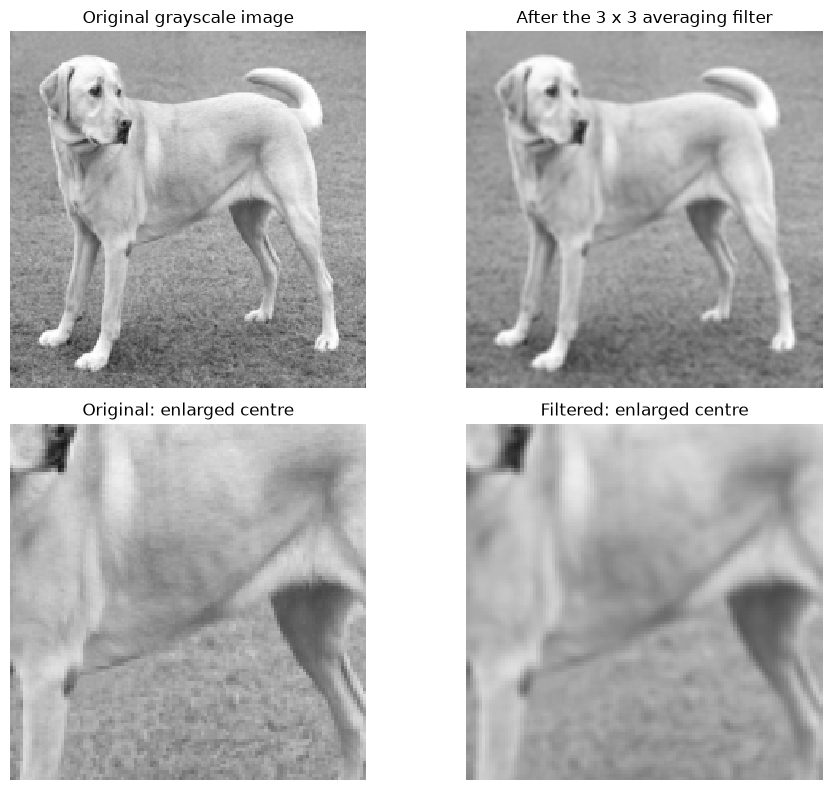

In [7]:
averaging_kernel = np.ones((3, 3), dtype=np.float32) / 9.0

# TODO 3A: Apply the averaging kernel to gray_values.
smoothed = apply_filter(gray_values,averaging_kernel)
if smoothed is None:
    raise NotImplementedError("Complete Exercise 3A before continuing.")

assert smoothed.shape == gray_values.shape, "Keep the image height and width."
print("Averaging kernel:")
print(averaging_kernel)

height, width = gray_values.shape
zoom = (slice(height // 4, 3 * height // 4),
        slice(width // 4, 3 * width // 4))
views = [
    (gray_values, "Original grayscale image"),
    (smoothed, "After the 3 x 3 averaging filter"),
    (gray_values[zoom], "Original: enlarged centre"),
    (smoothed[zoom], "Filtered: enlarged centre"),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for axis, (values, title) in zip(axes.flat, views):
    axis.imshow(values, cmap="gray", vmin=0, vmax=255,
                interpolation="nearest")
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()

### Exercise 3B: Highlight intensity changes

This Sobel kernel compares values on the right of a patch with values on the left. It responds to **left-to-right brightness changes**, so it often highlights vertical edges.

Apply `sobel_kernel` to the **original `gray_values`**, using the same helper. Store the result in `output`.

The response has a sign: positive and negative values represent opposite directions of brightness change. A larger absolute value indicates a stronger change in this direction. Negative values are valid responses.

In the colour plot, **blue means negative, light grey means close to zero and red means positive**. These colours show computed responses rather than the photograph's original colours.

<details><summary>Hint</summary>
Use <code>apply_filter(gray_values, sobel_kernel)</code>. Keep the signed result as floating-point values.
</details>

Sobel kernel:
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]
Sobel response range: -576.0 to 711.0


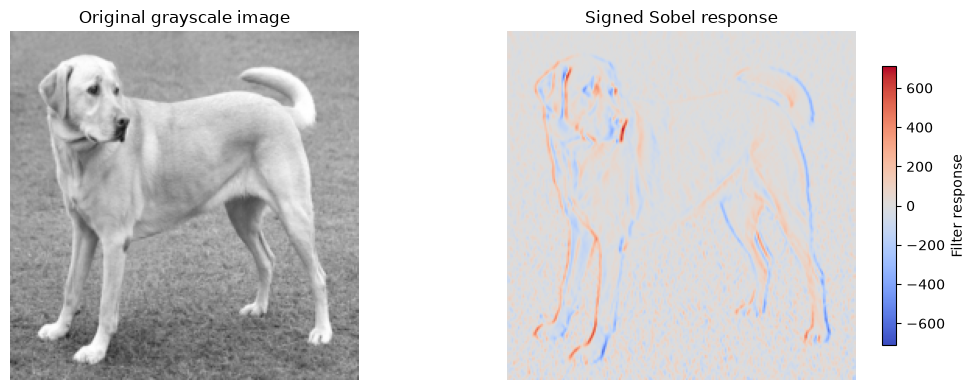

In [8]:
sobel_kernel = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1],
], dtype=np.float32)

# TODO 3B: Apply the Sobel kernel to the original gray_values.
output = apply_filter(gray_values,sobel_kernel)
if output is None:
    raise NotImplementedError("Complete Exercise 3B before continuing.")

assert output.shape == gray_values.shape, "Keep the image height and width."
print("Sobel kernel:")
print(sobel_kernel)
print("Sobel response range:", float(output.min()), "to", float(output.max()))

response_limit = max(float(np.max(np.abs(output))), 1.0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(gray_values, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original grayscale image")
response_plot = axes[1].imshow(
    output, cmap="coolwarm", vmin=-response_limit, vmax=response_limit
)
axes[1].set_title("Signed Sobel response")
for axis in axes:
    axis.axis("off")
fig.colorbar(response_plot, ax=axes[1], label="Filter response", shrink=0.8)
plt.tight_layout()
plt.show()

### Exercise 3C: Apply ReLU

ReLU keeps positive values and replaces negative values with zero. Run the next cell, which applies it in one line:

```python
relu_output = np.maximum(0, output)
```

Compare the two plots. They use **the same colour scale**, so you can see which responses change. ReLU operates on the filter's output values and keeps the feature map's shape unchanged.

Before ReLU: -576.0 to 711.0
After ReLU: 0.0 to 711.0
Negative responses replaced by zero: 24219


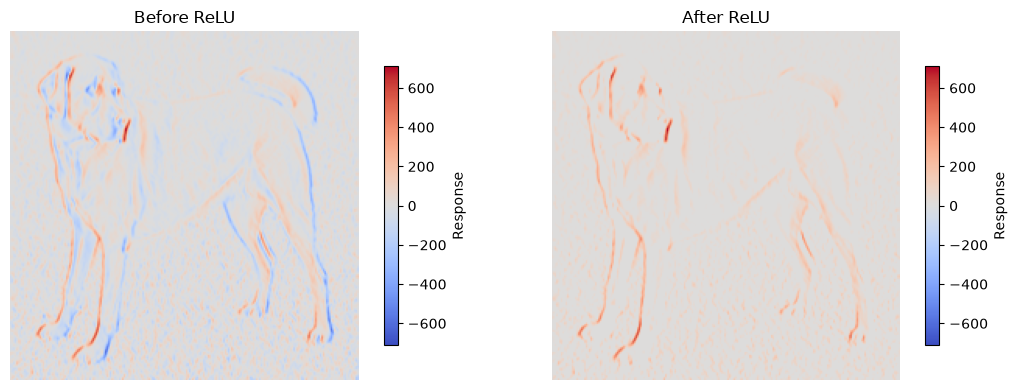

In [9]:
relu_output = np.maximum(0, output)

print("Before ReLU:", float(output.min()), "to", float(output.max()))
print("After ReLU:", float(relu_output.min()), "to", float(relu_output.max()))
print("Negative responses replaced by zero:", int(np.count_nonzero(output < 0)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, values, title in zip(
    axes, [output, relu_output], ["Before ReLU", "After ReLU"]
):
    response_plot = axis.imshow(
        values, cmap="coolwarm", vmin=-response_limit, vmax=response_limit
    )
    axis.set_title(title)
    axis.axis("off")
    fig.colorbar(response_plot, ax=axis, label="Response", shrink=0.8)
plt.tight_layout()
plt.show()

### Compare and explain

1. Which details become less distinct after averaging? Why does combining neighbouring values smooth the image?
2. Where does the Sobel kernel produce strong positive or negative responses? How do its weights differ from the averaging kernel's weights?
3. Which Sobel responses disappear after ReLU, and which stay unchanged? Does a negative response mean the filter made a mistake?
4. Who selected the two kernels in this exercise? How does this differ from a CNN learning filter weights during training?

**Your observations**

- Averaging filter: ...
- Sobel filter: ...
- Effect of ReLU: ...
- Hand-chosen and learned weights: ...

### Connecting this to a CNN

The same filtering operation produces different results depending on its weights: averaging smooths nearby values, while Sobel highlights intensity changes. ReLU then applies a nonlinear transformation by setting negative responses to zero.

Here, we chose the kernel weights ourselves. **A CNN learns its filter weights during training.** Our pretrained model already has learned weights, which remain fixed when we use it for prediction.

Next, we will inspect the feature maps produced by its learned filters.



## Learned feature maps

The supplied cell displays six feature maps from **MobileNetV2’s first convolution layer**, using the same image.

Each map records how one learned filter responds at different locations. These are the convolution outputs **before the following activation function.**

Look for differences in where the filters respond. These maps show internal patterns; they do not directly identify objects or explain the final prediction.

Each panel uses its own colour scale. Compare where responses occur, rather than comparing brightness between panels.

Prepared input shape: (1, 224, 224, 3)
Layer: Conv1
Feature map shape (height, width, channels): (112, 112, 32)


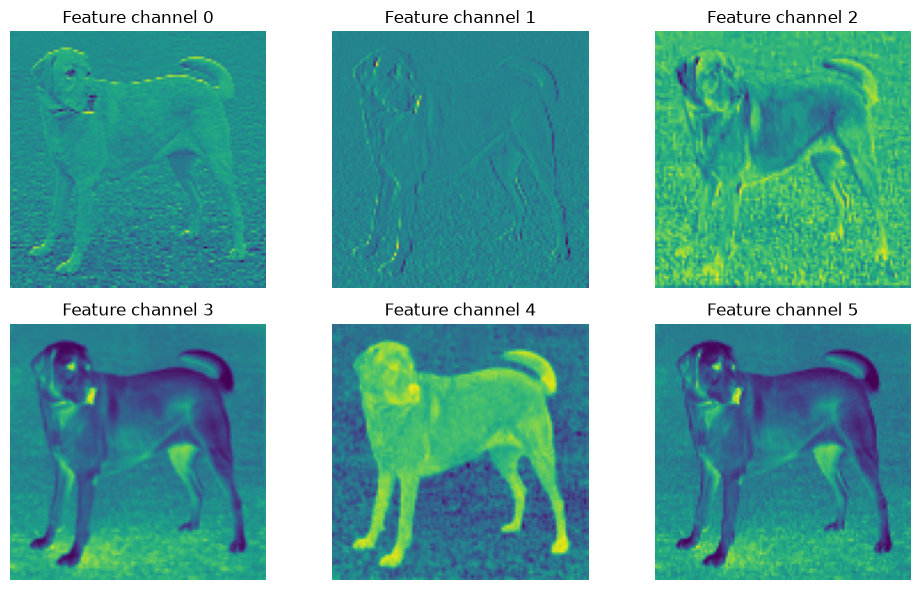

In [10]:
model = MobileNetV2(weights="imagenet", include_top=True)

# Prepare a separate copy for this feature-map demonstration.
feature_array = np.array(image_array, dtype=np.float32, copy=True)

# Add a batch dimension: (224, 224, 3) → (1, 224, 224, 3).
feature_batch = np.expand_dims(feature_array, axis=0)

# Scale pixel values from [0, 255] to [-1, 1].
feature_input = preprocess_input(feature_batch)

first_conv = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Conv2D)
)

feature_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=first_conv.output
)

# Extract the feature maps for the first and only image.
feature_maps = feature_model.predict(feature_input, verbose=0)[0]

print("Prepared input shape:", feature_input.shape)
print("Layer:", first_conv.name)
print(
    "Feature map shape (height, width, channels):",
    feature_maps.shape
)

fig, axes = plt.subplots(2, 3, figsize=(10, 6))

for channel, axis in enumerate(axes.flat):
    axis.imshow(feature_maps[:, :, channel], cmap="viridis")
    axis.set_title(f"Feature channel {channel}")
    axis.axis("off")

plt.tight_layout()
plt.show()

# Section 3: Image classification with a pretrained CNN

> **Guiding question 3:** How can we turn these numbers into a label for the photo?

MobileNetV2 is a **Convolutional Neural Network**, or CNN. Its convolutional layers use learned filters to respond to local patterns. Later layers combine earlier representations into information useful for classification.

`weights="imagenet"` loads parameters learned from ImageNet. We keep the existing classifier, which scores 1,000 ImageNet categories. The supplied cell loads the model once.

| Process | What happens |
| --- | --- |
| Training | Labelled examples and a loss guide changes to learned parameters |
| Inference | An existing model uses its learned parameters to make predictions |
| Transfer learning | We reuse a pretrained representation and train a classifier for a new task, with optional further fine-tuning |

This notebook demonstrates **inference**. Simply uploading a photo does not train or adapt the model.

We have explored fixed filters. Now let the pretrained CNN analyse the original RGB image using its learned filters. After the first prediction, we will also classify the averaged RGB version.


## Exercise 4: Add a batch dimension

The model expects **(batch size, height, width, channels)**. For one photo, this is `(1, 224, 224, 3)`.

Replace `None` with code that adds a new dimension at axis 0.

<details><summary>Hint</summary>
Use NumPy's `expand_dims` function on `image_array`, with `axis=0`. This groups the image into a batch containing one example.
</details>

In [11]:
# TODO 4: Add a dimension at axis 0 to image_array.
batch = np.expand_dims(image_array,axis = 0)
if batch is None:
    raise NotImplementedError("Complete Exercise 4 before continuing.")

print("Batch shape:", batch.shape)
assert batch.shape == (1, 224, 224, 3), "The first dimension should count one image."

Batch shape: (1, 224, 224, 3)


## Exercise 5: Apply model-specific preprocessing

MobileNetV2 expects values scaled from `[0, 255]` into `[-1, 1]`. Call its `preprocess_input` function on a copy of `batch` to create `x`.

Do not divide by 255 first. MobileNetV2's preprocessing already performs the required scaling. Another model may use another convention.

<details><summary>Hint</summary>
`preprocess_input` is already imported from MobileNetV2. Pass it `batch.copy()` so the original 0-255 values remain available for comparison.
</details>

In [12]:
# TODO 5: Apply preprocess_input to a copy of batch.
x = preprocess_input(batch.copy())
if x is None:
    raise NotImplementedError("Complete Exercise 5 before continuing.")

print("Original first pixel:", batch[0, 0, 0])
print("Preprocessed first pixel:", x[0, 0, 0])
print("Input shape:", x.shape)
print("Input range:", float(x.min()), "to", float(x.max()))
assert np.allclose(x, batch / 127.5 - 1.0), "Check model-specific scaling."

Original first pixel: [155. 160.  95.]
Preprocessed first pixel: [ 0.21568632  0.254902   -0.25490195]
Input shape: (1, 224, 224, 3)
Input range: -0.9607843160629272 to 1.0


## Exercise 6: Run the classifier

Call the model's `predict` method on `x`. The supplied decoder converts category indices into readable labels and shows the highest-scoring categories.

<details><summary>Hint</summary>
Use `model.predict(x, verbose=0)`. `verbose=0` hides the progress bar. This method makes predictions without a training step.
</details>

In [13]:
# TODO 6: Predict on x using the loaded model.
predictions = model.predict(x, verbose = 0)
if predictions is None:
    raise NotImplementedError("Complete Exercise 6 before continuing.")

top_k = 3  # Try 5 after your first successful run.
top_predictions = decode_predictions(predictions, top=top_k)[0]
print("Prediction shape:", predictions.shape)
for rank, (_, label, score) in enumerate(top_predictions, start=1):
    print(f"{rank}. {label.replace('_', ' ')}: {score:.1%}")

Prediction shape: (1, 1000)
1. Labrador retriever: 27.5%
2. Saluki: 8.6%
3. Ibizan hound: 3.6%


## Interpreting the result

> **Guiding question 4:** What do the labels and scores tell us, and what can we conclude?

The classifier scores the **whole image**. ImageNet includes detailed categories, such as particular dog breeds. A category may be more specific than the broad label you had in mind.

The default final layer uses **softmax** (a function turning a vector of raw, unnormalized numbers into a clean probability distribution), so all 1,000 scores sum to approximately 1. The top three alone need not sum to 100%.

**Discussion questions**

1. Is the highest-scoring label a reasonable description of the photograph?
2. Is a score of 90% the same as 90% test accuracy?
3. If two objects appear in a photo, will this classifier locate both of them?
4. What happens if the true subject has no matching ImageNet category?

Write your interpretation in the answer cell below. Look at the photo and the printed results before making a claim.

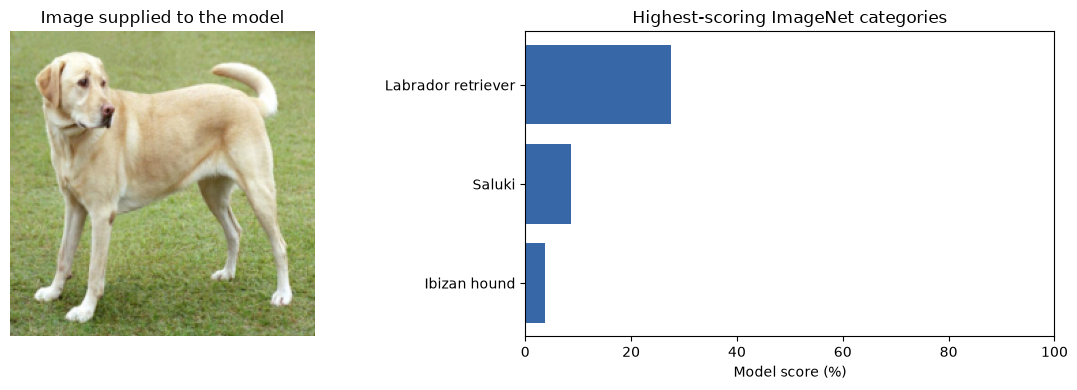

Sum over all categories: 1.0


In [14]:
labels = [label.replace("_", " ") for _, label, _ in top_predictions]
scores = [float(score) * 100 for _, _, score in top_predictions]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(model_img)
axes[0].set_title("Image supplied to the model")
axes[0].axis("off")
axes[1].barh(labels, scores, color="#3767a6")
axes[1].invert_yaxis()
axes[1].set_xlim(0, 100)
axes[1].set_xlabel("Model score (%)")
axes[1].set_title("Highest-scoring ImageNet categories")
plt.tight_layout()
plt.show()

print("Sum over all categories:", float(predictions.sum()))

### Your interpretation

- Highest-scoring label and score: ...
- Why the label seems reasonable or unreasonable: ...
- One limitation of the result: ...

# Section 4: How does changing the input affect the prediction?

>**Guiding question 5:** How does blurring an image affect the model’s prediction?

The supplied code compares the same image at **blur radii 0 (original), 4 and 12.** Blur is applied after resizing, and each version passes through the same preprocessing and pretrained model.

**Before running:** Predict whether the top label and its softmax score will change.

**After running:** Compare the results. The label may stay the same or change, and scores may rise or fall.

Only the input changes. **The model’s learned parameters remain fixed.**

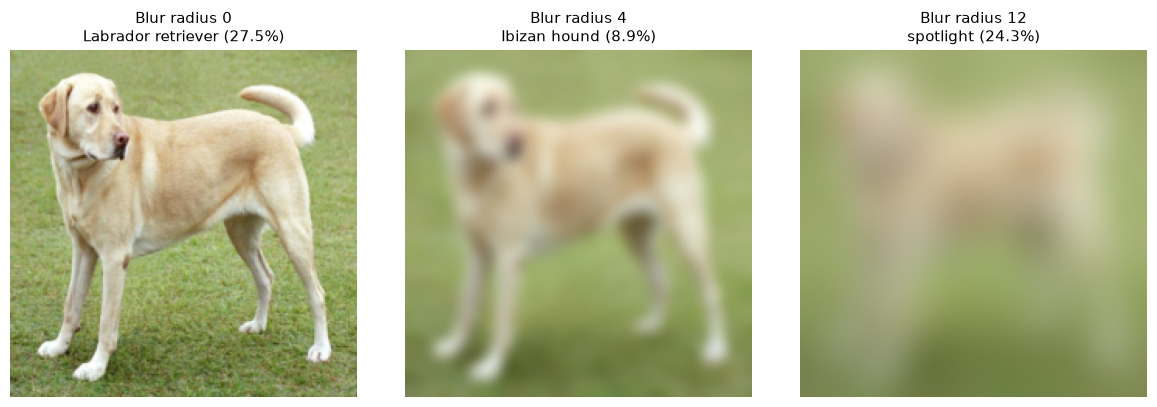

Radius  0: Labrador_retriever       27.5%
Radius  4: Ibizan_hound             8.9%
Radius 12: spotlight                24.3%


In [15]:
blur_radii = [0, 4, 12]  # Try a different positive radius after the first comparison.
results = []
fig, axes = plt.subplots(1, len(blur_radii), figsize=(12, 4))

for axis, radius in zip(axes, blur_radii):
    changed_img = model_img.filter(ImageFilter.GaussianBlur(radius=radius))
    changed_batch = np.expand_dims(np.asarray(changed_img, dtype=np.float32), axis=0)
    changed_x = preprocess_input(changed_batch.copy())
    changed_predictions = model.predict(changed_x, verbose=0)
    _, label, score = decode_predictions(changed_predictions, top=1)[0][0]
    results.append({"blur_radius": radius, "label": label, "score": float(score)})
    axis.imshow(changed_img)
    axis.set_title(f"Blur radius {radius}\n{label.replace('_', ' ')} ({score:.1%})", fontsize=11)
    axis.axis("off")

plt.tight_layout()
plt.show()
for result in results:
    print(f"Radius {result['blur_radius']:>2}: {result['label']:<24} {result['score']:.1%}")

### Observation questions

- Did the highest-scoring label change? At which blur radius?
- Did its score increase or decrease?
- Which details disappeared from the photograph?
- Can this experiment on one photo establish that the model is reliable across a collection of photos? What further evidence would you need?

**Your observations:** ...

# Section 5: Your turn

Choose **one question** below and investigate it with a new image. Change `image_source` to `"upload"`, rerun the image-loading cell, then rerun Sections 1-3 for the new image. Keep the already-loaded model by skipping its loading cell. Rerun the comparisons in Section 4 if your question involves filtering or blur.

- Does the model suggest a sensible label for a clear photo of an everyday object?
- How does it respond to a cluttered scene containing several objects?
- How does it respond to an SDS logo or another subject outside its existing categories?

### Your task

1. State your question and your expected outcome.
2. Run the code and record the actual highest-scoring label and score.
3. Describe whether the suggestion is useful for photo tagging or in general, knowing what the image is about.
4. State one limitation and one practical improvement you would investigate.

Do not treat a wrong prediction as a failed activity. It gives us something useful to explain. If your selected label seems sensible, that result alone still does not establish overall model accuracy.

| Item | Your answer |
| --- | --- |
| Question | ... |
| Expected outcome | ... |
| Image description | ... |
| Actual label and score | ... |
| Interpretation | ... |
| Limitation and proposed improvement | ... |

For a real application, define the intended categories, obtain labelled examples from the intended setting, and evaluate the system on separate examples.

## Troubleshooting

| Symptom | Next step |
| --- | --- |
| Message says to complete an exercise | Replace that exercise’s `None` with your code and rerun the cell |
| No kernel selected or wrong Python version | Click **Select Kernel** and choose your workshop’s **Python 3.12** environment |
| `ModuleNotFoundError` | Select the workshop kernel. In the VS Code terminal, activate that environment and run `python -m pip install -r requirements.txt`. Restart the kernel afterwards |
| `NameError` | Run earlier cells in order, especially after restarting the kernel |
| `FileNotFoundError` | Open the **week-10-cv** folder in VS Code. Check the file path in the loading cell. The included sample photo is at `data/images/sample.jpg` |
| Image cannot be opened | Use a JPEG or PNG. Export HEIC phone photos to JPEG first |
| Model weights or labels cannot download | Check your internet connection and rerun the model-loading or prediction cell that failed |
| Model rejects the input shape | Check that the input is RGB, resized, and grouped into a batch. For one image, the final model input should have shape **(1, 224, 224, 3)** |
| Prediction seems wrong | Check the photo and MobileNetV2 preprocessing. The model can only choose among its **1,000 ImageNet classes**, so unfamiliar images can receive incorrect labels |

After changing `image_path`, rerun the image-loading cell and all subsequent cells. After changing only `top_k`, rerun the prediction and result-plotting cells.

## References

- [VS Code notebook kernels](https://code.visualstudio.com/docs/datascience/jupyter-kernel-management): selecting the Python environment used to run notebook cells.
- [TensorFlow MobileNetV2 API](https://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV2): model input, pretrained parameters and categories.
- [MobileNetV2 preprocessing](https://www.tensorflow.org/api_docs/python/tf/keras/applications/mobilenet_v2/preprocess_input): input scaling.
- [Keras Applications](https://keras.io/api/applications/): pretrained image classification workflow.
- [TensorFlow Keras Model API](https://www.tensorflow.org/api_docs/python/tf/keras/Model): extracting intermediate tensors.
- [TensorFlow transfer learning tutorial](https://www.tensorflow.org/tutorials/images/transfer_learning): adaptation to new categories.
- [NumPy padding](https://numpy.org/doc/stable/reference/generated/numpy.pad.html): repeating border values in the filter helper.
- [Sobel kernels](https://docs.opencv.org/4.x/d2/d2c/tutorial_sobel_derivatives.html): the Sobel operation and its directional responses.
- [NumPy maximum](https://numpy.org/doc/stable/reference/generated/numpy.maximum.html): the elementwise operation used for ReLU.
- [Pillow image filters](https://pillow.readthedocs.io/en/stable/reference/ImageFilter.html): the supplied fixed edge-filter illustration.
- [TensorFlow sample-image tutorial](https://www.tensorflow.org/tutorials/generative/adversarial_fgsm): source of the Labrador example. This notebook does not implement the tutorial's adversarial attack.
- Sample image: [Wikimedia Commons file page](https://commons.wikimedia.org/wiki/File:YellowLabradorLooking_new.jpg), original Elf photo, derivative/retouch by Djmirko and FT2, [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/).
